# Практическая работа по лекции 2. Декомпозиция и сглаживание

**Выполнил: Голубенко Никита.**

**Цель работы:** выделить тренд, две сезонные компоненты и остаток, проверить, как выбор метода декомпозиции влияет на интерпретацию ряда.

## Данные и схема эксперимента

Для лабораторных используется собственный генератор временных рядов из первой работы. Для этой лабораторной он адаптирован к **почасовой частоте** и двум периодам, которые требует лекция 2: **24 часа** (суточная сезонность) и **168 часов** (недельная сезонность).

Синтетический ряд создаётся на период с 01.01.2023 по 31.12.2024. Он содержит линейный тренд, суточную и недельную сезонности, небольшое увеличение уровня с заданной даты и контролируемые точечные выбросы.

Все три метода применяются к одному и тому же ряду. Для полноценного сравнения представлены **четыре набора компонент**: известные компоненты, заложенные в генератор, классическая декомпозиция, STL и MSTL. Истинные компоненты служат эталоном, поскольку их значения известны из формулы генерации. Выбор аддитивной или log-additive шкалы дополнительно обосновывается графиком связи среднего дневного уровня и амплитуды.

## 1. Импорт библиотек и параметры генерации

Используется `MSTL` из `statsmodels`, поэтому требуется `statsmodels >= 0.14`. Для частотного алиаса `h` используется `pandas >= 2.2`.

```bash
pip install numpy "pandas>=2.2" matplotlib "statsmodels>=0.14"
```


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf
import statsmodels

_pandas_version = tuple(int(part) for part in pd.__version__.split('.')[:2])
if _pandas_version < (2, 2):
    raise RuntimeError('Требуется pandas >= 2.2. Установите: pip install -U \"pandas>=2.2\"')
if tuple(int(part) for part in statsmodels.__version__.split('.')[:2]) < (0, 14):
    raise RuntimeError('Требуется statsmodels >= 0.14 для MSTL.')

SEED = 42
START = '2023-01-01 00:00:00'
N_DAYS = 731                         # 2023 + високосный 2024 год
N_POINTS = N_DAYS * 24
FREQ = 'h'
DAILY_PERIOD = 24
WEEKLY_PERIOD = 24 * 7
OUTPUT_DIR = Path('results_lecture2_decomposition')
OUTPUT_DIR.mkdir(exist_ok=True)

print('pandas:', pd.__version__, '| statsmodels:', statsmodels.__version__)
print('Частота:', FREQ)
print('Периоды сезонности:', DAILY_PERIOD, 'и', WEEKLY_PERIOD, 'часов')
print('Количество точек:', N_POINTS)

pandas: 3.0.0 | statsmodels: 0.15.0
Частота: h
Периоды сезонности: 24 и 168 часов
Количество точек: 17544


## 2. Генерация ряда с трендом, двумя сезонностями, выбросами и сдвигом уровня

Функция ниже — расширение генератора первой лабораторной. В отличие от первой версии, здесь можно задать почасовую сетку и отдельные периоды сезонности. Недельная составляющая задаётся эффектами дней недели, суточная — гармоническим профилем внутри дня. Это создаёт реалистичную календарную структуру для демонстрации MSTL.

In [2]:
def generate_hourly_multiseasonal_series(
    n_points=N_POINTS,
    start=START,
    seed=SEED,
    daily_period=24,
    weekly_period=168,
    noise_start=7.0,
    noise_end=10.0,
    level_shift_start='2024-03-01 00:00:00',
    level_shift=18.0,
    n_outliers=12,
):
    """Генерирует ряд и возвращает как наблюдения, так и известные компоненты."""
    if n_points < 2 * weekly_period:
        raise ValueError('Для сравнения суточной и недельной сезонностей нужно не менее двух недель данных.')
    if daily_period != 24 or weekly_period != 168:
        raise ValueError('В этой лабораторной ожидаются периоды 24 и 168 часов.')

    rng = np.random.default_rng(seed)
    index = pd.date_range(start=start, periods=n_points, freq=FREQ, name='timestamp')
    t = np.arange(n_points, dtype=float)
    hour = index.hour.to_numpy()
    weekday = index.dayofweek.to_numpy()

    # Истинный линейный тренд.
    linear_trend = 155.0 + 0.0025 * t

    # Суточная сезонность: два характерных подъёма в течение дня.
    daily = (
        42.0 * np.sin(2 * np.pi * (hour - 8) / daily_period)
        + 16.0 * np.sin(4 * np.pi * (hour - 8) / daily_period)
    )

    # Недельная сезонность: разные уровни в будни и выходные.
    weekday_effect = np.array([14.0, 16.0, 15.0, 12.0, 9.0, -27.0, -31.0])
    weekly = weekday_effect[weekday] + 4.0 * np.sin(2 * np.pi * t / weekly_period)

    # Умеренно меняющаяся дисперсия шума.
    noise_scale = np.linspace(noise_start, noise_end, n_points)
    noise = rng.normal(0.0, noise_scale, n_points)

    # Ряд до внесения сдвига уровня и выбросов.
    series_before_perturbations = linear_trend + daily + weekly + noise

    # Небольшой контролируемый сдвиг уровня.
    shift_timestamp = pd.Timestamp(level_shift_start)
    level_shift_component = np.where(index >= shift_timestamp, level_shift, 0.0)
    shifted = series_before_perturbations + level_shift_component

    # Точечные выбросы с известными индексами и направлениями.
    eligible = np.arange(24, n_points - 24)
    outlier_indices = np.sort(rng.choice(eligible, size=n_outliers, replace=False))
    signs = np.array([1.0] * (n_outliers // 2) + [-1.0] * (n_outliers - n_outliers // 2))
    rng.shuffle(signs)
    magnitudes = rng.uniform(150.0, 230.0, size=n_outliers)
    contaminated = shifted.copy()
    for idx, sign, magnitude in zip(outlier_indices, signs, magnitudes):
        contaminated[idx] = max(0.0, contaminated[idx] + sign * magnitude)

    # Фактический эффект выброса учитывает возможное ограничение снизу нулём.
    outlier_effect = contaminated - shifted

    # Истинный набор четырёх компонент точно восстанавливает analysis_series:
    # тренд включает известный ступенчатый сдвиг, остаток включает шум и выбросы.
    true_components = pd.DataFrame({
        'trend_true': linear_trend + level_shift_component,
        'seasonal_24_true': daily,
        'seasonal_168_true': weekly,
        'resid_true': noise + outlier_effect,
        'linear_trend_without_shift': linear_trend,
        'level_shift_true': level_shift_component,
        'noise_true': noise,
        'outlier_effect_true': outlier_effect,
    }, index=index)

    metadata = {
        'n_points': n_points,
        'start': str(index.min()),
        'end': str(index.max()),
        'frequency': '1 час',
        'daily_period': daily_period,
        'weekly_period': weekly_period,
        'level_shift_start': str(shift_timestamp),
        'level_shift': level_shift,
        'n_outliers': len(outlier_indices),
        'seed': seed,
    }
    return (
        pd.Series(series_before_perturbations, index=index, name='series_before_perturbations'),
        pd.Series(contaminated, index=index, name='analysis_series'),
        true_components,
        outlier_indices,
        signs,
        magnitudes,
        metadata,
    )

series_before_perturbations, analysis_series, true_components, outlier_indices, outlier_signs, outlier_magnitudes, metadata = generate_hourly_multiseasonal_series()


reconstruction_error = (true_components[['trend_true', 'seasonal_24_true', 'seasonal_168_true', 'resid_true']].sum(axis=1) - analysis_series).abs().max()
if reconstruction_error > 1e-9:
    raise RuntimeError(f'Истинные компоненты не восстанавливают исходный ряд; max error={reconstruction_error}')

print('Параметры генерации:')
for key, value in metadata.items():
    print(f'  {key}: {value}')
print(f'Максимальная ошибка восстановления истинными компонентами: {reconstruction_error:.3e}')


Параметры генерации:
  n_points: 17544
  start: 2023-01-01 00:00:00
  end: 2024-12-31 23:00:00
  frequency: 1 час
  daily_period: 24
  weekly_period: 168
  level_shift_start: 2024-03-01 00:00:00
  level_shift: 18.0
  n_outliers: 12
  seed: 42
Максимальная ошибка восстановления истинными компонентами: 5.684e-14


## 3. Проверка сгенерированного ряда и искусственных событий

`series_before_perturbations` — ряд до внесения ступенчатого сдвига и точечных выбросов. `analysis_series` — итоговый ряд, который анализируется методами декомпозиции. `true_components` хранит известные компоненты генератора: истинный тренд (включая сдвиг уровня), суточную сезонность, недельную сезонность и остаток (шум вместе с эффектом выбросов). Их сумма точно восстанавливает `analysis_series` и образует четвёртый, эталонный набор компонент.


,Время,Тип,"Значение после сдвига, до выброса",Фактический эффект выброса,Значение после возмущения
0,2023-01-03 17:00:00,положительный выброс,193.03,183.95,376.98
1,2023-02-10 03:00:00,отрицательный выброс,113.08,-113.08,0.00
2,2023-04-15 07:00:00,положительный выброс,116.61,159.47,276.08
3,2023-06-02 13:00:00,отрицательный выброс,220.93,-211.06,9.87
4,2023-07-27 17:00:00,положительный выброс,192.92,219.07,411.99
5,2024-04-16 08:00:00,положительный выброс,215.08,186.56,401.64
6,2024-05-06 13:00:00,отрицательный выброс,268.74,-154.77,113.98
7,2024-05-28 13:00:00,положительный выброс,263.91,155.34,419.24
8,2024-09-05 04:00:00,отрицательный выброс,158.85,-158.85,0.00
9,2024-09-21 20:00:00,положительный выброс,186.85,223.49,410.34


,Показатель,Значение
0,Число наблюдений,17544
1,Частота,1 час
2,Пропущенные значения,0
3,Дубликаты временных меток,0
4,Искусственные выбросы,12
5,Начало сдвига уровня,2024-03-01 00:00:00
6,Величина сдвига,18.0


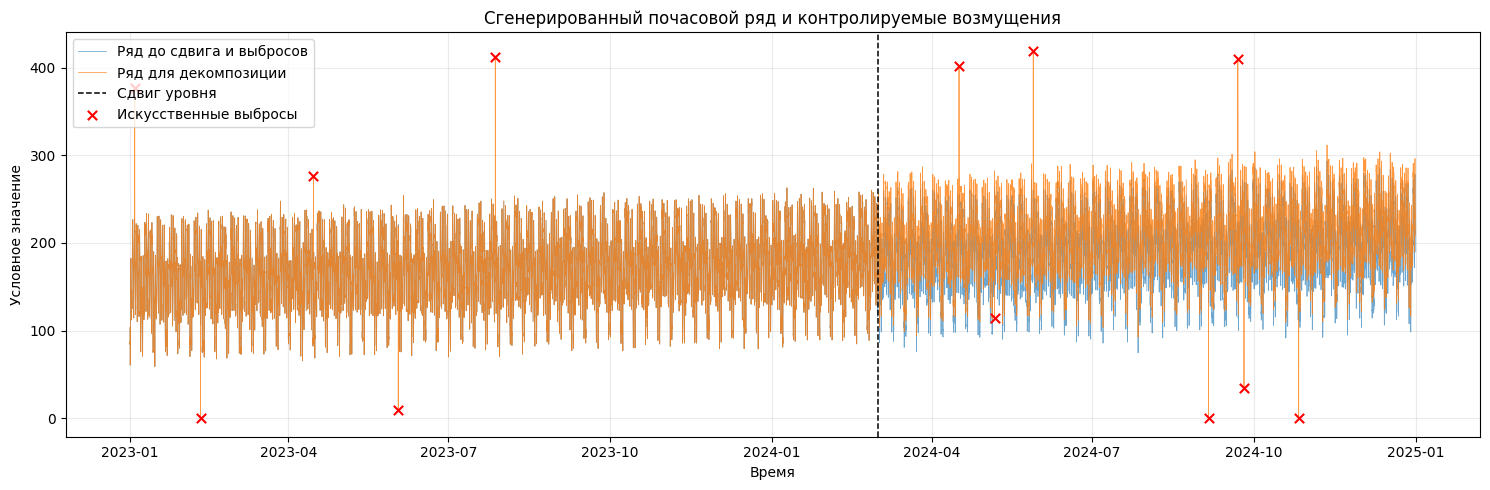

In [3]:
SHIFT_START = pd.Timestamp(metadata['level_shift_start'])
LEVEL_SHIFT = float(metadata['level_shift'])
event_rows = []
for idx, sign, magnitude in zip(outlier_indices, outlier_signs, outlier_magnitudes):
    event_rows.append({
        'Время': analysis_series.index[idx],
        'Тип': 'положительный выброс' if sign > 0 else 'отрицательный выброс',
        'Значение после сдвига, до выброса': float(series_before_perturbations.iloc[idx] + (LEVEL_SHIFT if analysis_series.index[idx] >= SHIFT_START else 0.0)),
        'Фактический эффект выброса': float(analysis_series.iloc[idx] - (series_before_perturbations.iloc[idx] + (LEVEL_SHIFT if analysis_series.index[idx] >= SHIFT_START else 0.0))),
        'Значение после возмущения': float(analysis_series.iloc[idx]),
    })
events_table = pd.DataFrame(event_rows).sort_values('Время')
events_table_display = events_table.copy()

numeric_cols = events_table_display.select_dtypes(include="number").columns

events_table_display[numeric_cols] = (
    events_table_display[numeric_cols].round(2)
)

display(events_table_display)

events_table.to_csv(OUTPUT_DIR / '01_injected_outliers.csv', index=False)

quality_summary = pd.DataFrame({
    'Показатель': [
        'Число наблюдений', 'Частота', 'Пропущенные значения',
        'Дубликаты временных меток', 'Искусственные выбросы',
        'Начало сдвига уровня', 'Величина сдвига'
    ],
    'Значение': [
        len(analysis_series), '1 час', int(analysis_series.isna().sum()),
        int(analysis_series.index.duplicated().sum()), len(outlier_indices),
        SHIFT_START, metadata['level_shift']
    ]
})
display(quality_summary)
quality_summary.to_csv(OUTPUT_DIR / '02_series_summary.csv', index=False)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(series_before_perturbations.index, series_before_perturbations.values, linewidth=0.55, alpha=0.65, label='Ряд до сдвига и выбросов')
ax.plot(analysis_series.index, analysis_series.values, linewidth=0.55, alpha=0.8, label='Ряд для декомпозиции')
ax.axvline(SHIFT_START, color='black', linestyle='--', linewidth=1.1, label='Сдвиг уровня')
ax.scatter(events_table['Время'], events_table['Значение после возмущения'], color='red', marker='x', s=45, label='Искусственные выбросы', zorder=4)
ax.set_title('Сгенерированный почасовой ряд и контролируемые возмущения')
ax.set_xlabel('Время')
ax.set_ylabel('Условное значение')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_generated_series.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 4. Визуальный анализ: весь ряд, сезонные подсерии и тепловая карта

Строятся график всего ряда, увеличенный двухнедельный фрагмент, средние сезонные профили по часу и дню недели, а также тепловая карта «час × день недели».

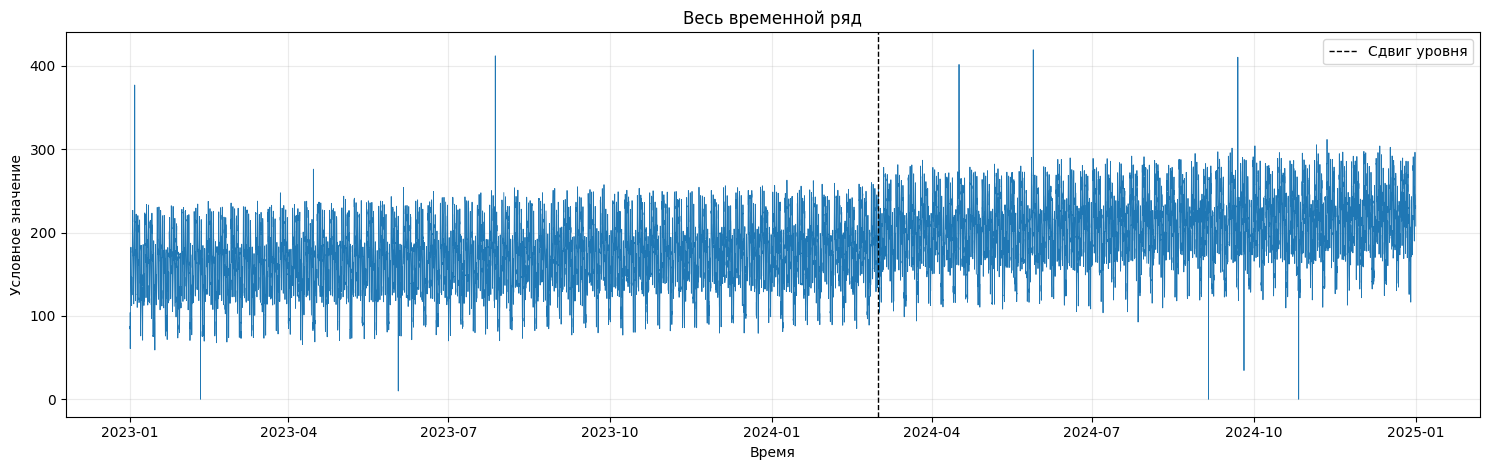

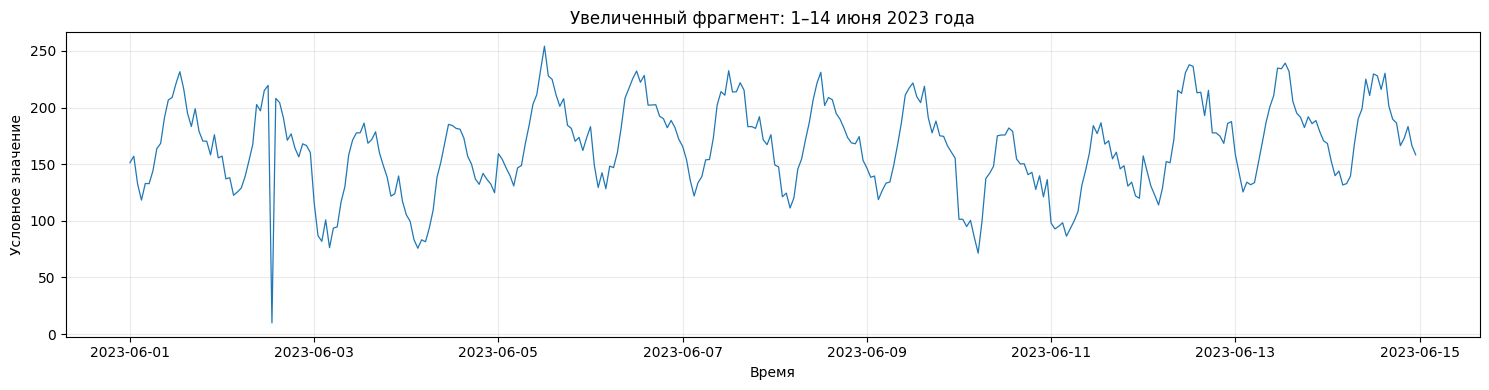

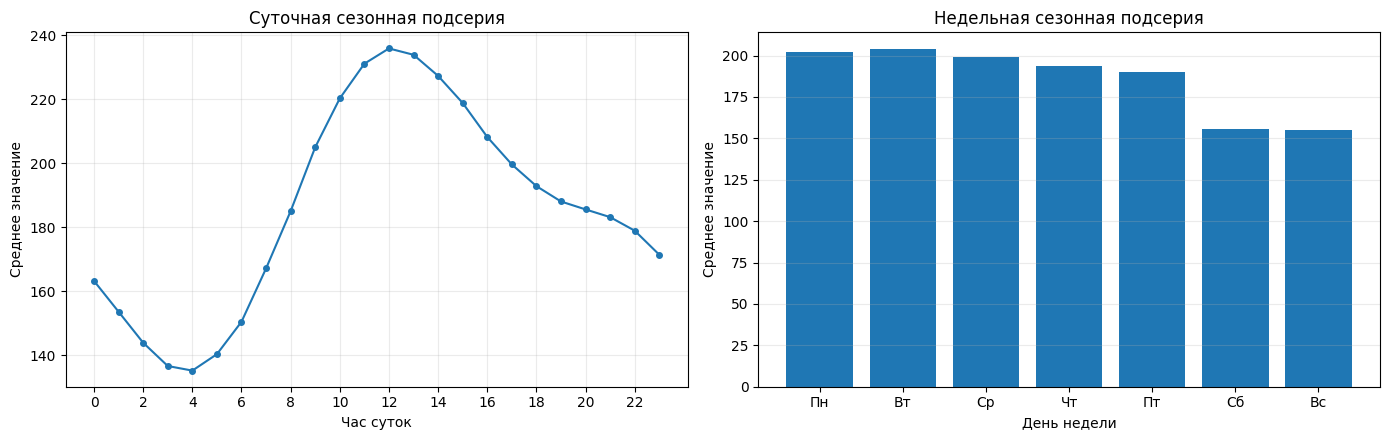

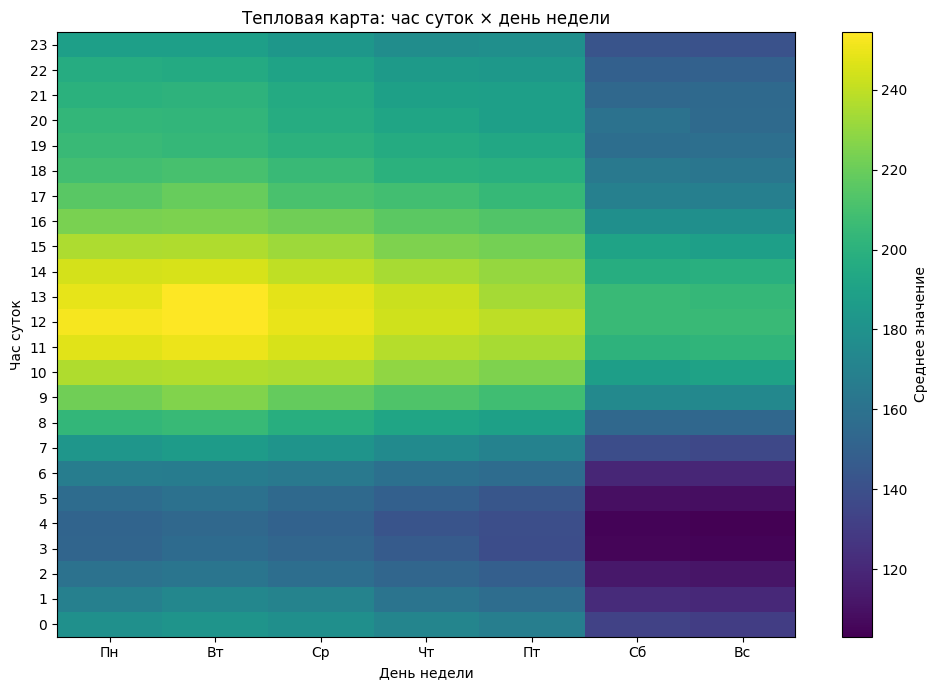

In [4]:
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.plot(analysis_series.index, analysis_series.values, linewidth=0.6)
ax.axvline(SHIFT_START, color='black', linestyle='--', linewidth=1, label='Сдвиг уровня')
ax.set_title('Весь временной ряд')
ax.set_xlabel('Время')
ax.set_ylabel('Условное значение')
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '04_full_series.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

zoom = analysis_series.loc['2023-06-01':'2023-06-14']
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(zoom.index, zoom.values, linewidth=0.9)
ax.set_title('Увеличенный фрагмент: 1–14 июня 2023 года')
ax.set_xlabel('Время')
ax.set_ylabel('Условное значение')
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '05_zoom_fragment.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

calendar = pd.DataFrame({'value': analysis_series})
calendar['hour'] = calendar.index.hour
calendar['weekday'] = calendar.index.dayofweek
weekday_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
hour_profile = calendar.groupby('hour')['value'].mean().reindex(range(24))
weekday_profile = calendar.groupby('weekday')['value'].mean().reindex(range(7))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hour_profile.index, hour_profile.values, marker='o', markersize=4)
axes[0].set_title('Суточная сезонная подсерия')
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Среднее значение')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, alpha=0.25)
axes[1].bar([weekday_labels[i] for i in weekday_profile.index], weekday_profile.values)
axes[1].set_title('Недельная сезонная подсерия')
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Среднее значение')
axes[1].grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '06_seasonal_subseries.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

heatmap = calendar.pivot_table(values='value', index='hour', columns='weekday', aggfunc='mean').reindex(index=range(24), columns=range(7))
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(heatmap.values, aspect='auto', origin='lower', interpolation='nearest')
ax.set_title('Тепловая карта: час суток × день недели')
ax.set_xlabel('День недели')
ax.set_ylabel('Час суток')
ax.set_xticks(range(7), weekday_labels)
ax.set_yticks(range(24))
fig.colorbar(im, ax=ax, label='Среднее значение')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '07_hour_weekday_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 5. Проверка суточной и недельной сезонности с помощью ACF

Для почасового ряда проверяются пики автокорреляции на лагах 24 и 168. Значимые пики на этих расстояниях поддерживают наличие соответствующих циклов.

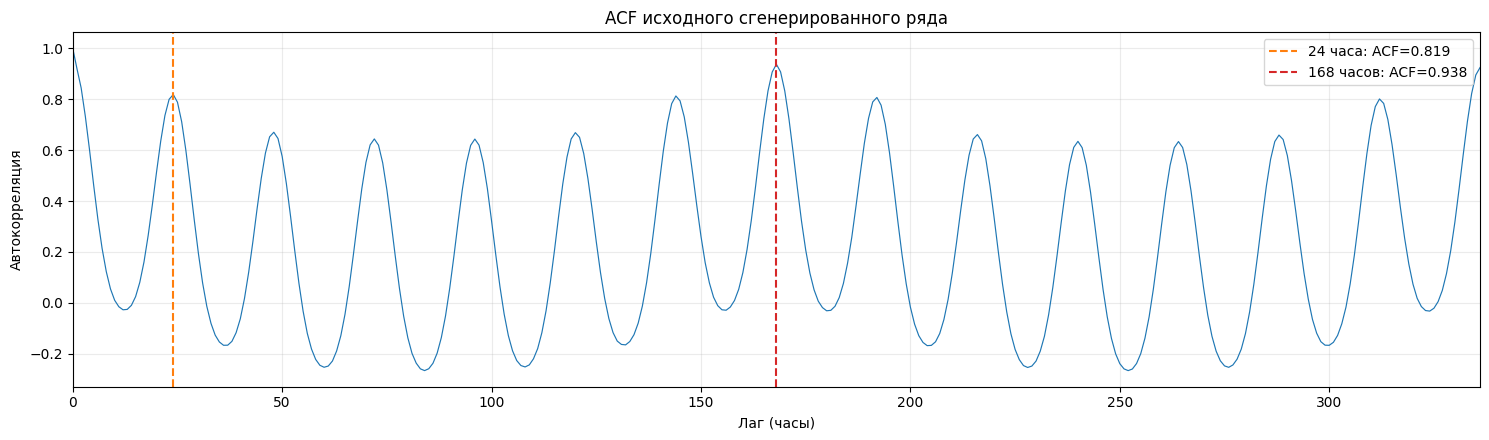

In [5]:
acf_original = acf(analysis_series, nlags=336, fft=True)
acf_at_24 = float(acf_original[24])
acf_at_168 = float(acf_original[168])

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(np.arange(len(acf_original)), acf_original, linewidth=0.85)
ax.axvline(24, color='tab:orange', linestyle='--', label=f'24 часа: ACF={acf_at_24:.3f}')
ax.axvline(168, color='tab:red', linestyle='--', label=f'168 часов: ACF={acf_at_168:.3f}')
ax.set_xlim(0, 336)
ax.set_title('ACF исходного сгенерированного ряда')
ax.set_xlabel('Лаг (часы)')
ax.set_ylabel('Автокорреляция')
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '08_acf_original.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. Выбор аддитивной или log-additive шкалы

Согласно лекции, тип модели выбирается по тому, меняется ли абсолютная амплитуда сезонности вместе с уровнем ряда. Для этого оценивается связь среднего дневного значения с суточной амплитудой. Если связь выраженная положительная, применяется `log1p`, после чего аддитивная декомпозиция соответствует log-additive форме. В противном случае используется исходная шкала.

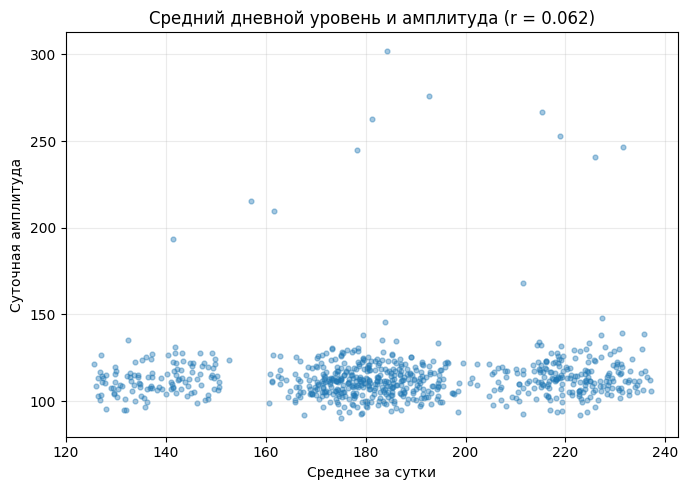

Выбранная шкала декомпозиции: additive: value
Корреляция дневного среднего и суточной амплитуды: 0.062


In [6]:
daily_stats = analysis_series.resample('D').agg(['mean', 'max', 'min'])
daily_stats['amplitude'] = daily_stats['max'] - daily_stats['min']
amplitude_corr = float(daily_stats[['mean', 'amplitude']].corr().iloc[0, 1])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(daily_stats['mean'], daily_stats['amplitude'], alpha=0.4, s=12)
ax.set_title(f'Средний дневной уровень и амплитуда (r = {amplitude_corr:.3f})')
ax.set_xlabel('Среднее за сутки')
ax.set_ylabel('Суточная амплитуда')
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '09_level_amplitude_diagnostic.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

if amplitude_corr >= 0.50:
    decomposition_series = np.log1p(analysis_series).rename('log1p_value')
    model_scale = 'log-additive: log1p(value)'
else:
    decomposition_series = analysis_series.rename('value')
    model_scale = 'additive: value'
print('Выбранная шкала декомпозиции:', model_scale)
print(f'Корреляция дневного среднего и суточной амплитуды: {amplitude_corr:.3f}')

## 7. Классическая декомпозиция с `period=24`

Классическая декомпозиция выделяет одну сезонную компоненту. В данном случае выделяется суточный профиль. Недельный цикл не выделяется как отдельная компонента и может частично сохраняться как в тренде, так и в остатке. Из-за центрированного скользящего среднего теряются оценки на краях ряда.

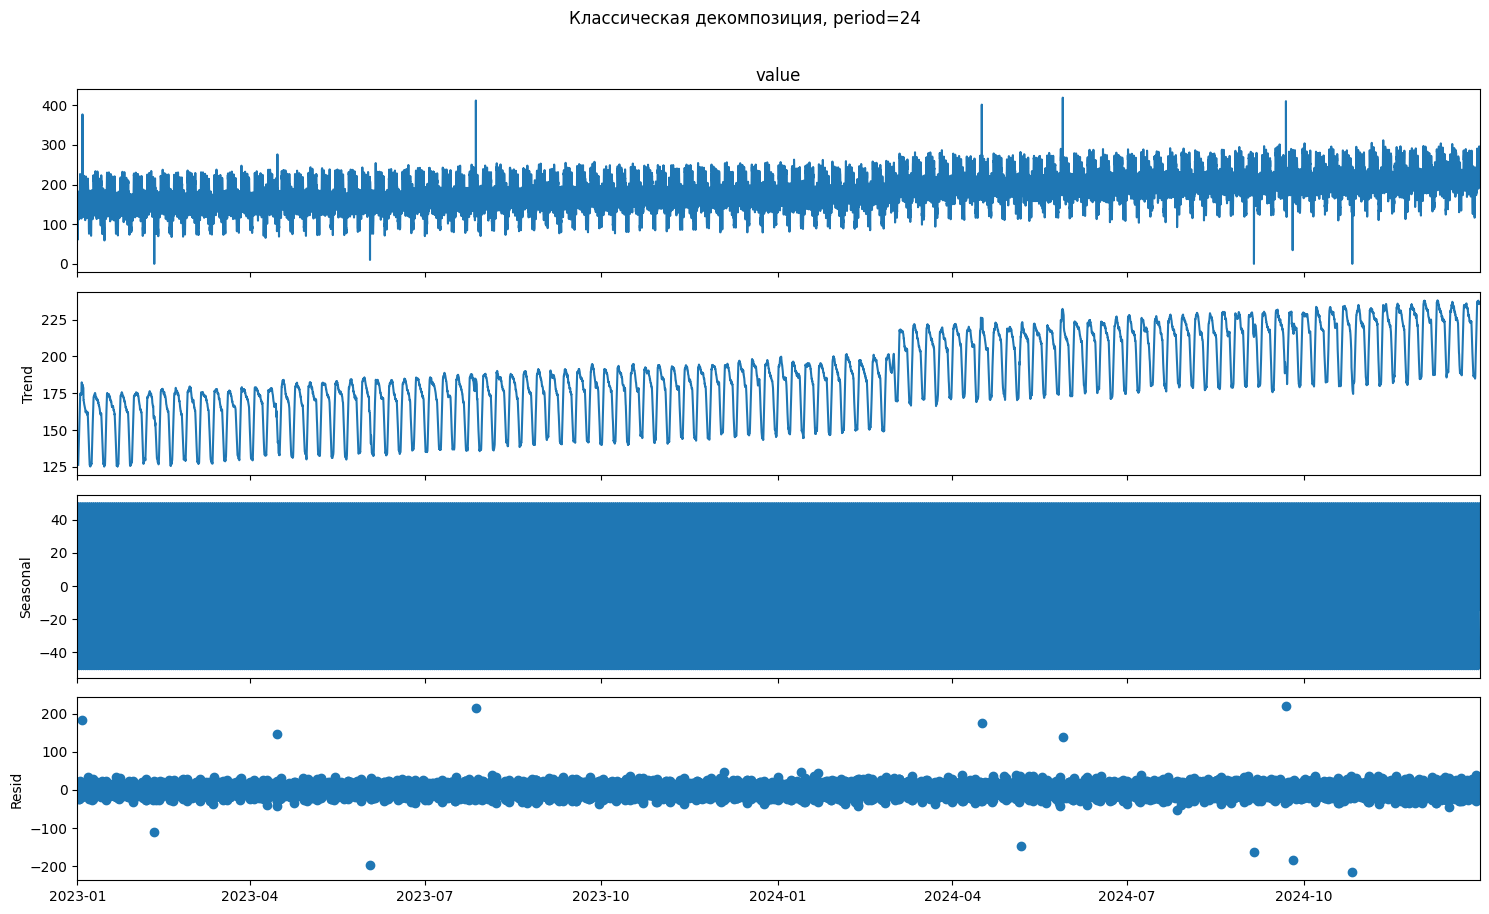

In [7]:
classic_result = seasonal_decompose(
    decomposition_series, model='additive', period=24,
    two_sided=True, extrapolate_trend=0
)
fig = classic_result.plot()
fig.set_size_inches(15, 9)
fig.suptitle('Классическая декомпозиция, period=24', y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '10_classical_decomposition.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)
classic_resid = classic_result.resid

## 8. STL с `period=24` и `robust=True`

STL использует LOESS и робастные веса. Задано `seasonal=13` — нечётное окно сезонного сглаживания. Оно выбрано как компромисс: допускает медленную эволюцию суточного профиля, но не позволяет сезонной компоненте подстраиваться под каждый краткосрочный шумовой всплеск. Поскольку сезонный профиль в нашем генераторе стабилен, более крупное нечётное окно (например, `seasonal=25`) также было бы обоснованно для заведомо стабильного профиля, здесь оставлено 13, чтобы показать гибкость STL.

Параметр `trend=169` — нечётное окно тренда примерно на одну неделю. Оно выделяет плавное долгосрочное движение, но сглаживает искусственный ступенчатый сдвиг уровня: скачок не обязан появиться в тренде как вертикальная ступенька и может распределиться по соседним часам. Имеем ожидаемый эффект сглаживания, а не ошибку вычислений. Для более быстрой реакции на сдвиг можно уменьшить `trend` и сравнить результат.


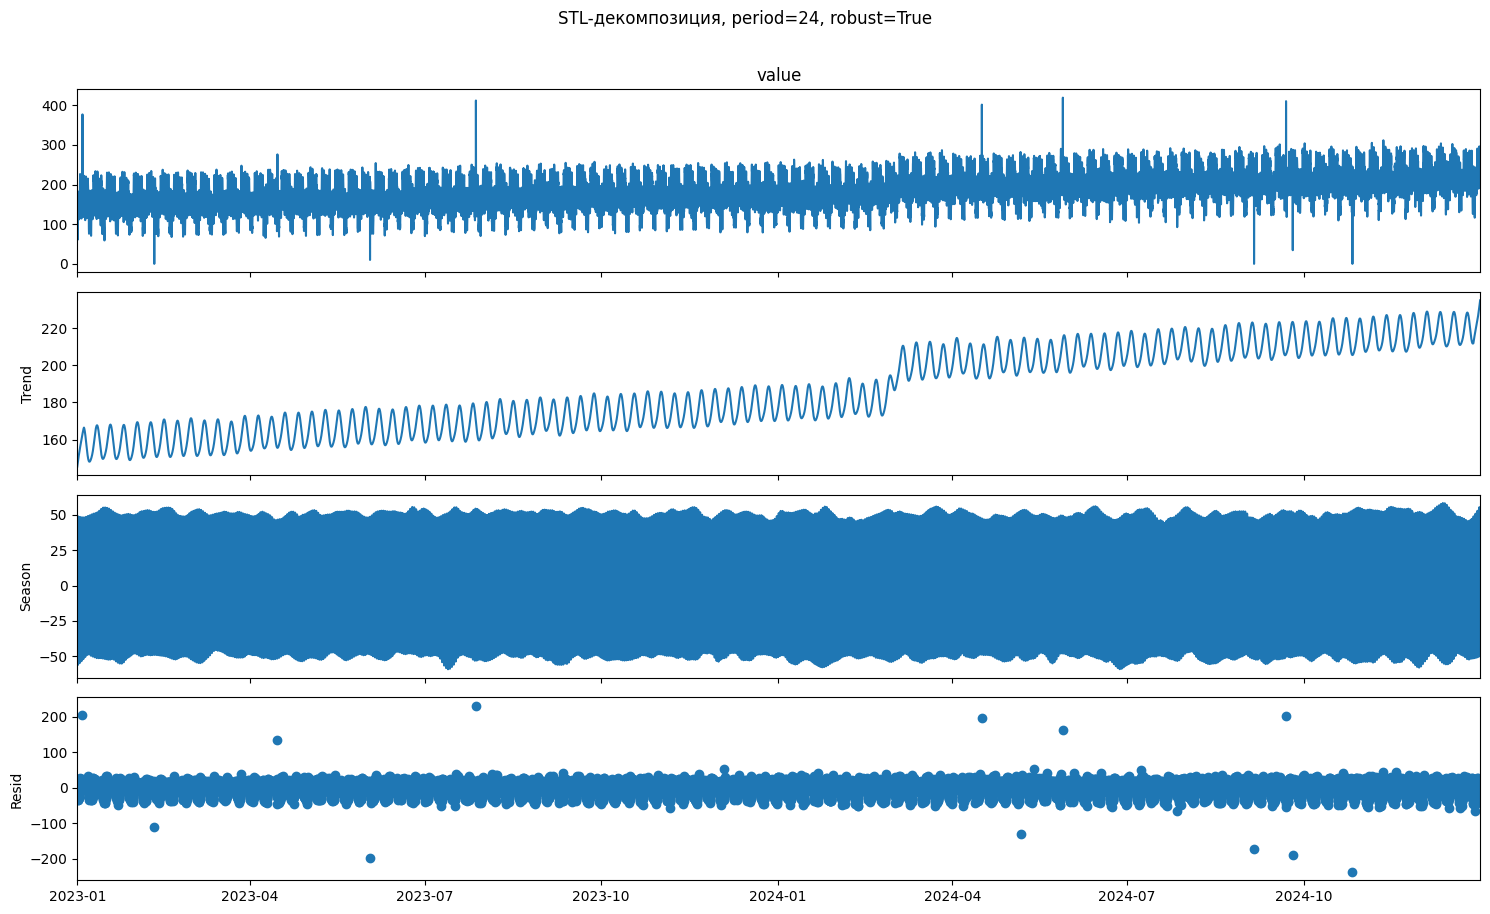

In [8]:
stl_result = STL(
    decomposition_series,
    period=24,
    seasonal=13,
    trend=169,
    robust=True,
).fit()
fig = stl_result.plot()
fig.set_size_inches(15, 9)
fig.suptitle('STL-декомпозиция, period=24, robust=True', y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '11_stl_decomposition.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)
stl_resid = stl_result.resid

## 9. MSTL с `periods=(24, 168)` и `robust=True`

MSTL итеративно извлекает две сезонные компоненты по отдельности: суточную (24 часа) и недельную (168 часов). Для обеих компонент заданы окна сглаживания `windows=(13, 13)`, число итераций уточнения — 2, устойчивость к выбросам включена через `stl_kwargs`.

Выбор `windows=(13, 13)` сделан для симметричного компромисса по двум сезонностям: оба окна нечётные и не меньше 7. В `statsmodels` для двух сезонностей стандартные значения по умолчанию обычно соответствуют `(11, 15)`.

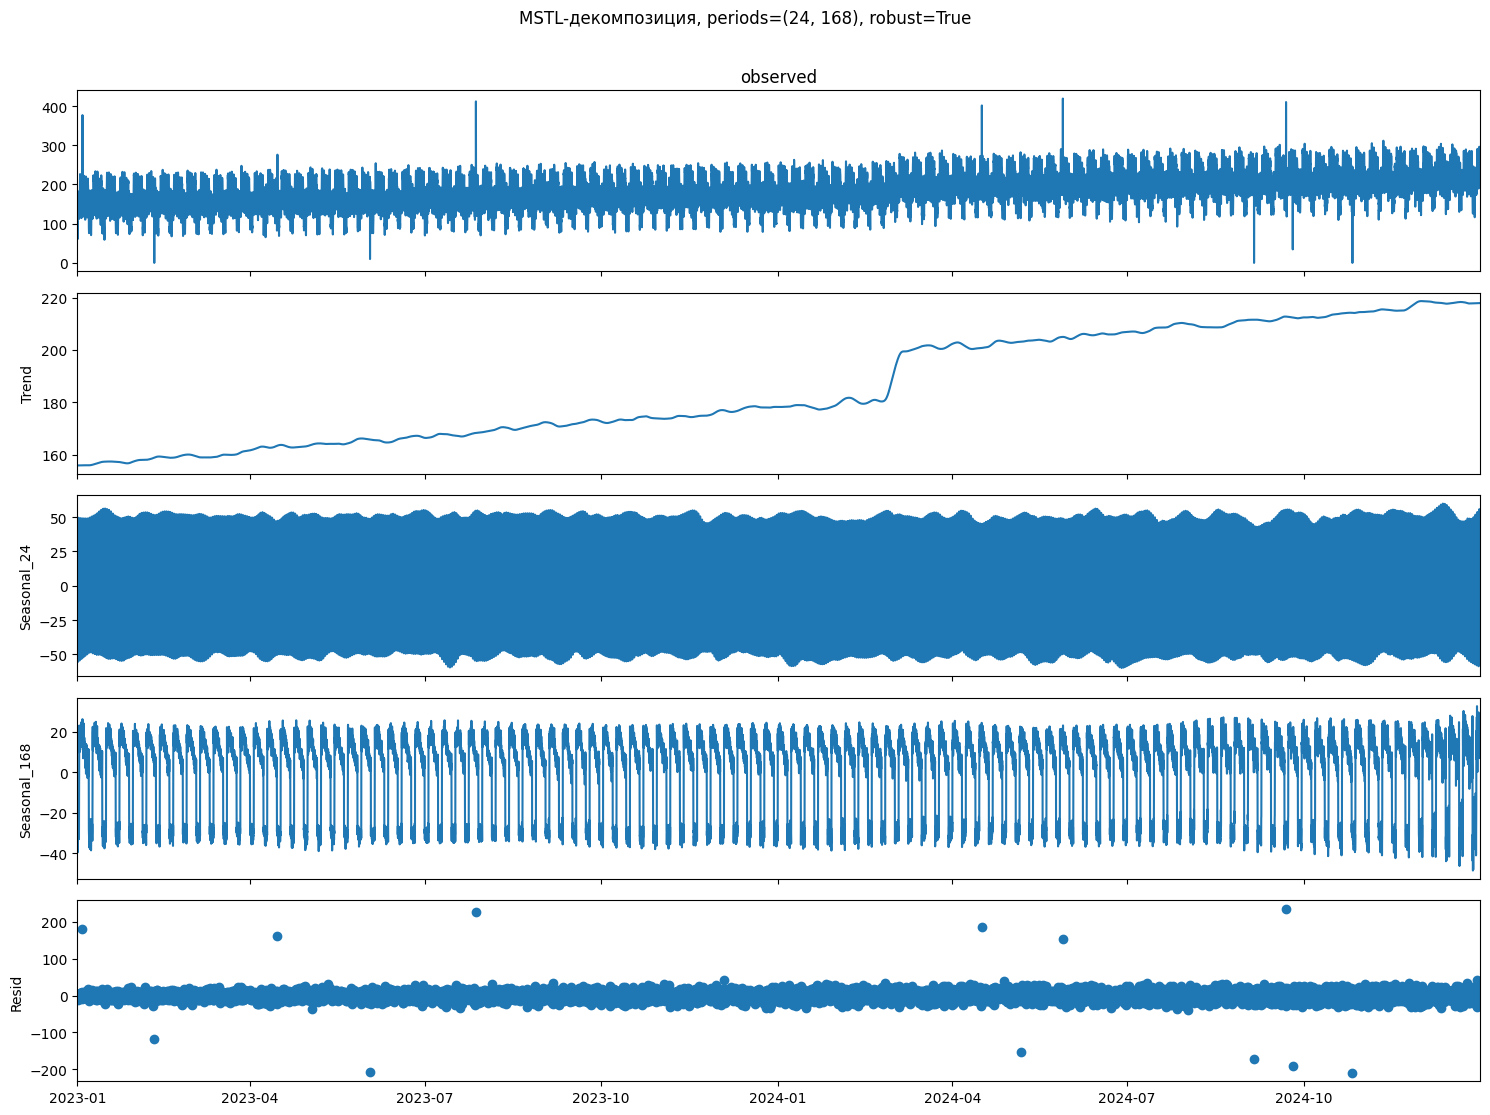

In [9]:
mstl_result = MSTL(
    decomposition_series,
    periods=(24, 168),
    windows=(13, 13),
    iterate=2,
    stl_kwargs={'robust': True},
).fit()
fig = mstl_result.plot()
fig.set_size_inches(15, 11)
fig.suptitle('MSTL-декомпозиция, periods=(24, 168), robust=True', y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '12_mstl_decomposition.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)
mstl_resid = mstl_result.resid

## 10. Количественное сравнение остатков

Для каждого метода рассчитываются дисперсия остатка и ACF остатков на лагах 24 и 168. Дисперсии рассчитываются на общей области, где все три метода возвращают значения, что исключает преимущество метода только из-за потери краёв. ACF дополнительно сравнивается визуально на лагах до 336.

,Метод,Дисперсия остатка (общие точки),"ACF остатка, лаг 24 (общие точки)","ACF остатка, лаг 168 (общие точки)",Число общих точек
0,Классическая,134.01423,0.01908,0.31102,17520
1,STL,317.21130,0.06349,0.72637,17520
2,MSTL,79.69897,-0.08905,-0.07151,17520


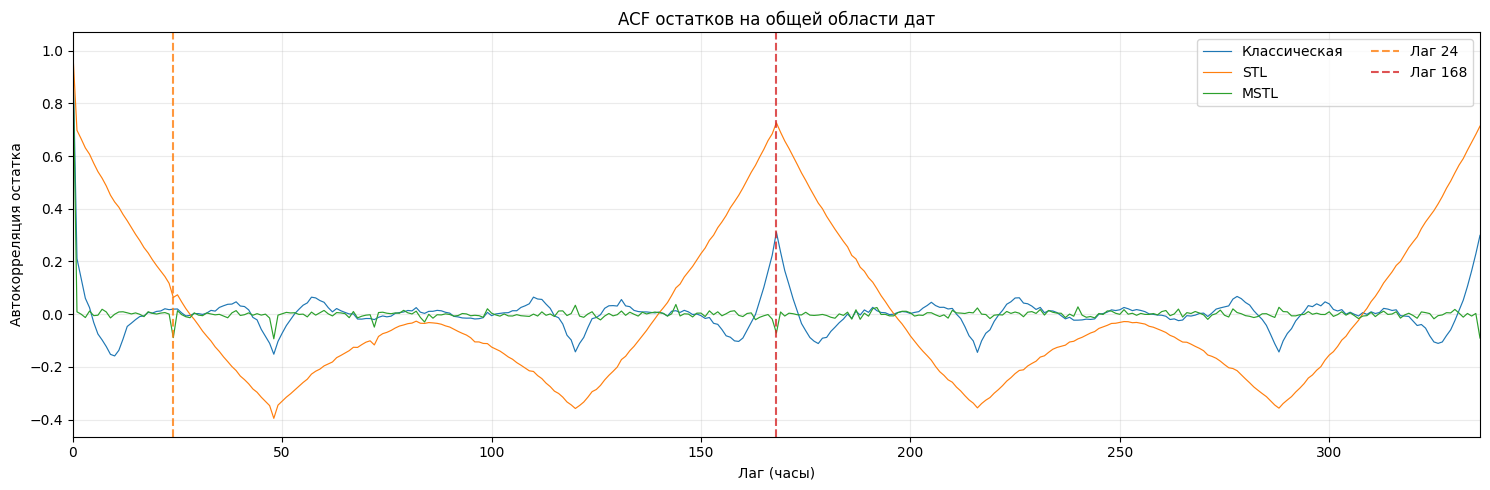

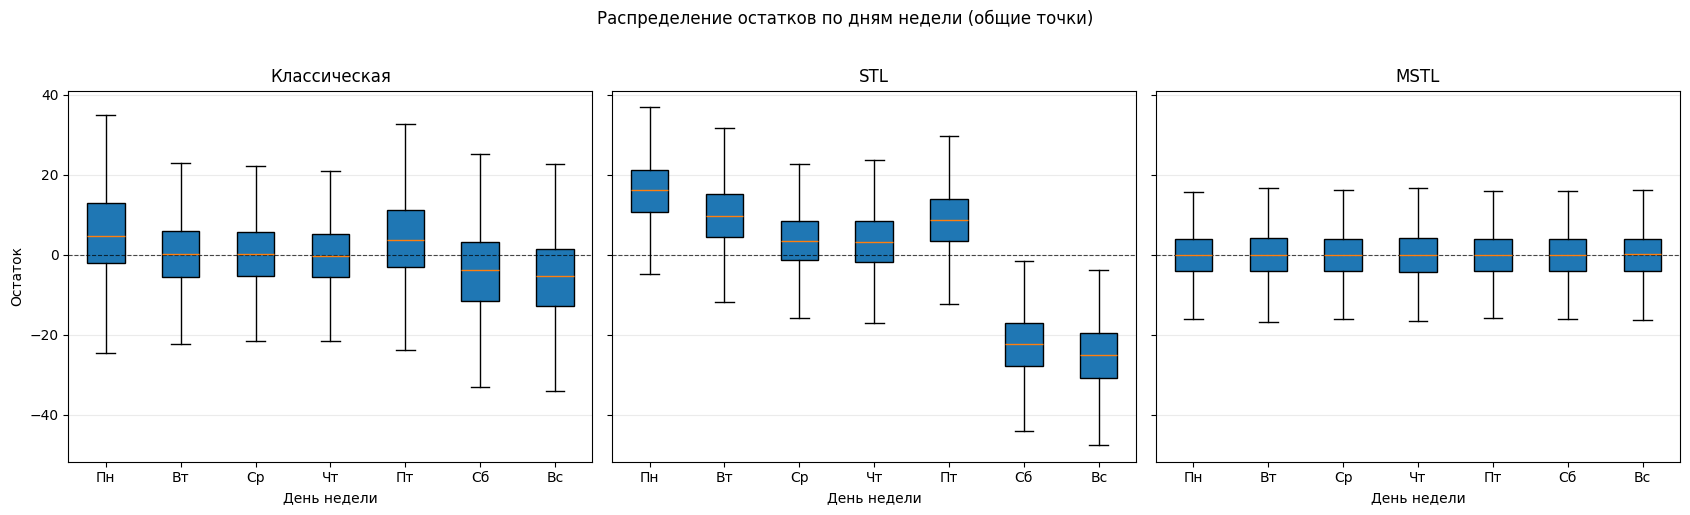

,Классическая,STL,MSTL
День недели,,,
Пн,4.666,16.168,0.069
Вт,0.118,9.678,-0.045
Ср,0.314,3.523,0.001
Чт,-0.223,3.274,-0.082
Пт,3.586,8.581,0.016
Сб,-3.691,-22.302,0.035
Вс,-5.351,-25.001,0.082


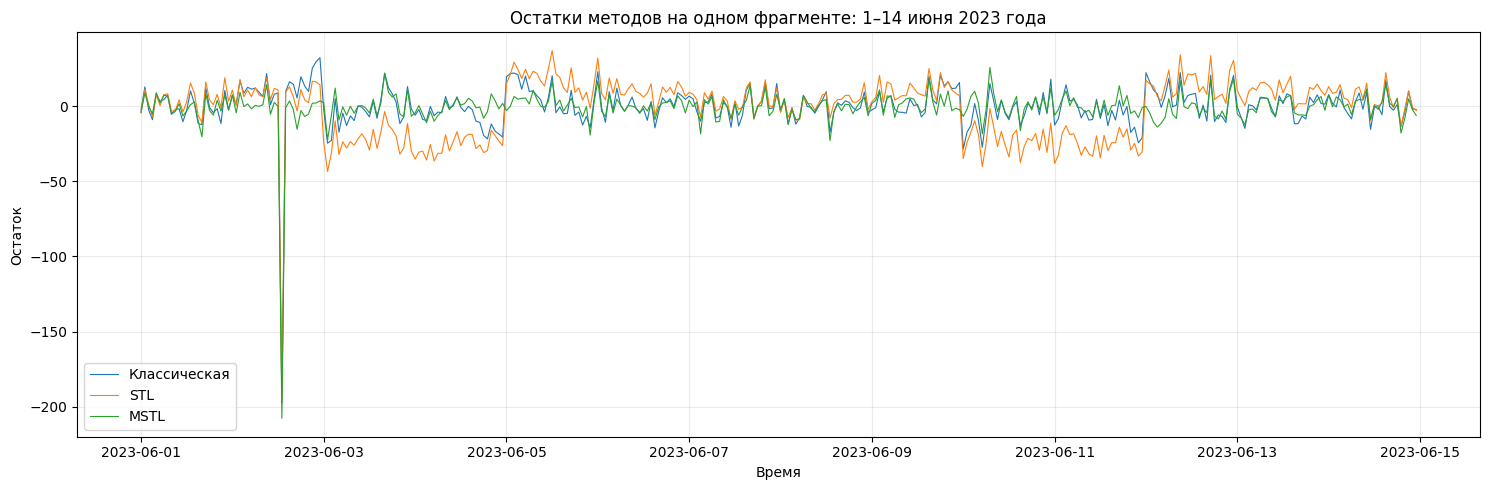

In [10]:
residuals = pd.concat({
    'Классическая': classic_resid,
    'STL': stl_resid,
    'MSTL': mstl_resid,
}, axis=1)
common_residuals = residuals.dropna()
comparison_rows = []
for method in residuals.columns:
    # И дисперсия, и ACF рассчитываются на одной общей области дат.
    resid_common = common_residuals[method]
    resid_acf = acf(resid_common, nlags=168, fft=True)
    comparison_rows.append({
        'Метод': method,
        'Дисперсия остатка (общие точки)': float(resid_common.var(ddof=1)),
        'ACF остатка, лаг 24 (общие точки)': float(resid_acf[24]),
        'ACF остатка, лаг 168 (общие точки)': float(resid_acf[168]),
        'Число общих точек': int(resid_common.notna().sum()),
    })
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(5))
comparison_table.to_csv(OUTPUT_DIR / '13_residual_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(15, 5))
for method in common_residuals.columns:
    vals = common_residuals[method]
    resid_acf = acf(vals, nlags=336, fft=True)
    ax.plot(np.arange(len(resid_acf)), resid_acf, linewidth=0.85, label=method)
ax.axvline(24, color='tab:orange', linestyle='--', alpha=0.8, label='Лаг 24')
ax.axvline(168, color='tab:red', linestyle='--', alpha=0.8, label='Лаг 168')
ax.set_xlim(0, 336)
ax.set_title('ACF остатков на общей области дат')
ax.set_xlabel('Лаг (часы)')
ax.set_ylabel('Автокорреляция остатка')
ax.grid(True, alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '14_acf_residuals.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# Недельная сезонность, оставшаяся в остатках, проявляется в различиях
# распределений по дням недели. Сравниваем методы на общей временной области.
weekday_labels = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_codes = common_residuals.index.dayofweek
boxplot_label_kw = (
    {'tick_labels': weekday_labels}
    if tuple(int(part) for part in plt.matplotlib.__version__.split('.')[:2]) >= (3, 9)
    else {'labels': weekday_labels}
)
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, method in zip(axes, common_residuals.columns):
    groups = [common_residuals.loc[weekday_codes == day, method].dropna().values for day in range(7)]
    ax.boxplot(groups, showfliers=False, patch_artist=True, **boxplot_label_kw)
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.set_title(method)
    ax.set_xlabel('День недели')
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('Остаток')
fig.suptitle('Распределение остатков по дням недели (общие точки)', y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '15_residuals_by_weekday.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

weekday_median_table = common_residuals.groupby(common_residuals.index.dayofweek).median()
weekday_median_table.index = weekday_labels
weekday_median_table.index.name = 'День недели'
display(weekday_median_table.round(3))
weekday_median_table.to_csv(OUTPUT_DIR / '14_residual_medians_by_weekday.csv')

resid_zoom = common_residuals.loc['2023-06-01':'2023-06-14']
fig, ax = plt.subplots(figsize=(15, 5))
for method in resid_zoom.columns:
    ax.plot(resid_zoom.index, resid_zoom[method], linewidth=0.8, label=method)
ax.set_title('Остатки методов на одном фрагменте: 1–14 июня 2023 года')
ax.set_xlabel('Время')
ax.set_ylabel('Остаток')
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '16_residual_zoom.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)


## 11. Интерпретация компонентов MSTL

Первая сезонная компонента MSTL соответствует периоду 24 часа, вторая — 168 часов. Суточная компонента описывает внутридневной профиль, недельная — различия между часами разных дней недели. Тренд отражает долгосрочное изменение уровня после удаления обеих сезонностей.

Для проверки качества интерпретации дополнительно строится эталонный набор компонент, известный из генератора. В нём тренд включает ступенчатый сдвиг, суточная и недельная сезонности заданы отдельно, а остаток содержит шум и фактический эффект внесённых выбросов, что позволяет сравнить три оценки декомпозиции с известной конструкцией ряда.


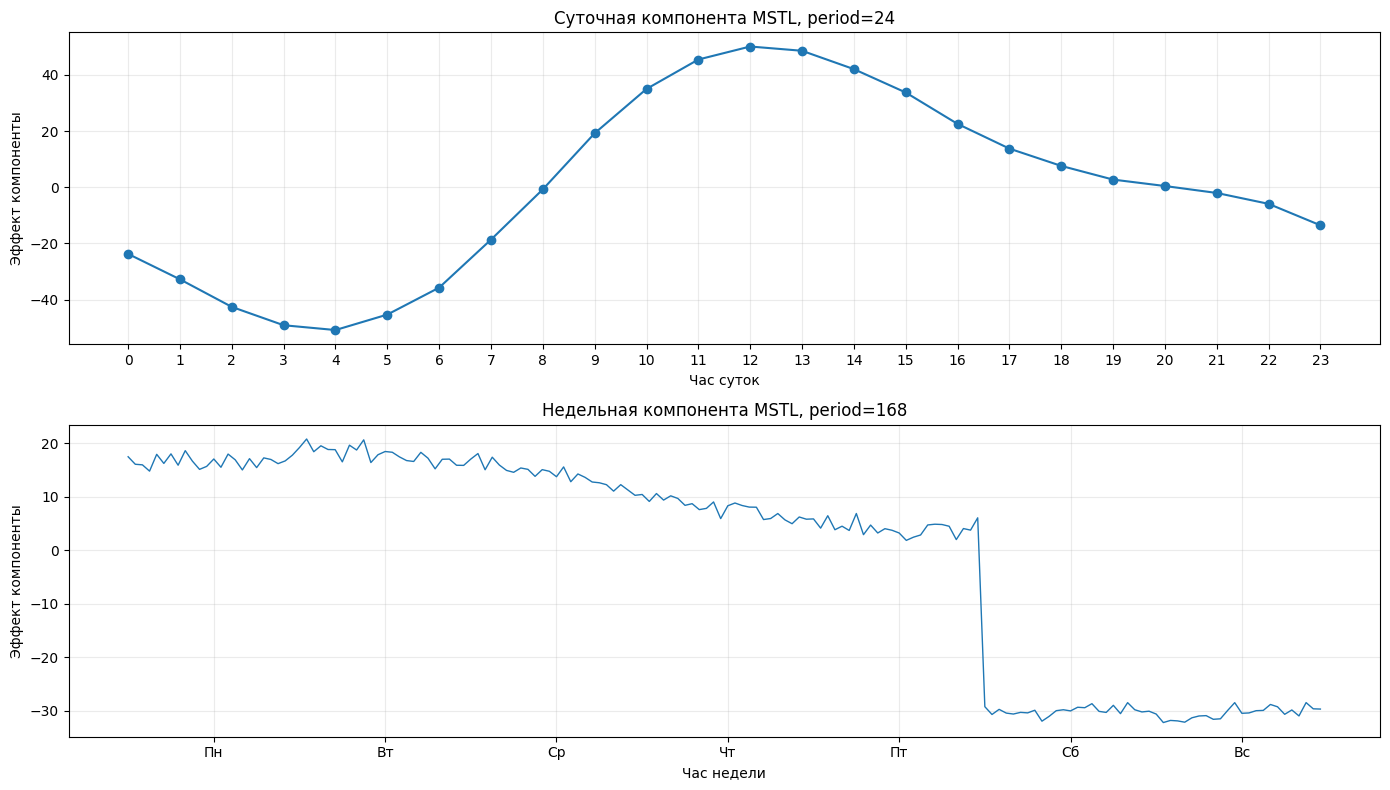

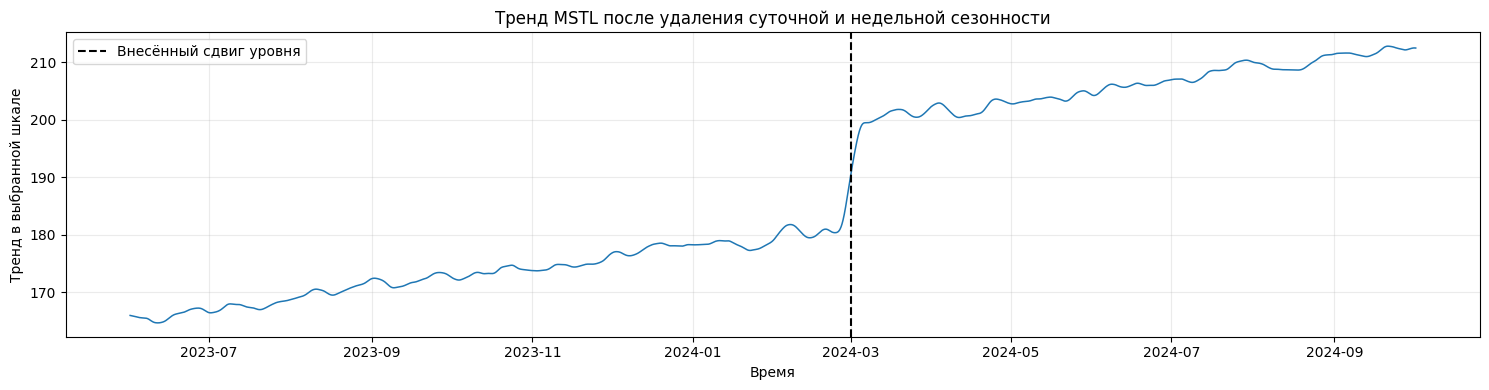

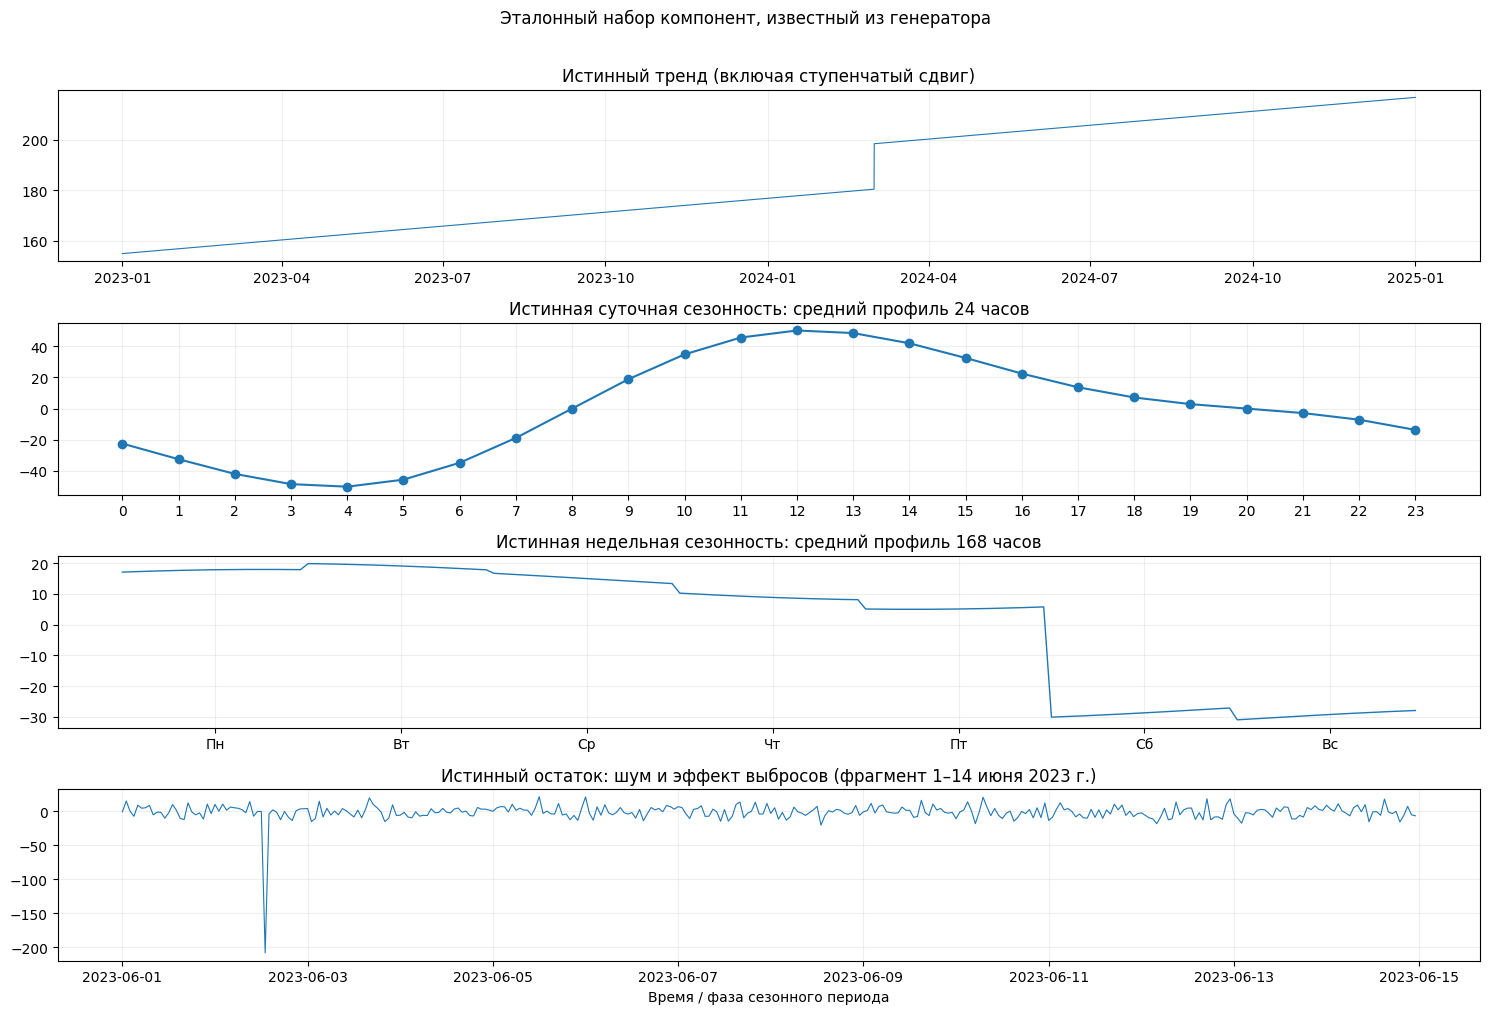

In [11]:
seasonal_components = mstl_result.seasonal
if isinstance(seasonal_components, pd.Series) or seasonal_components.shape[1] != 2:
    raise RuntimeError('Ожидались две сезонные компоненты MSTL для периодов 24 и 168.')

seasonal_24 = seasonal_components.iloc[:, 0]
seasonal_168 = seasonal_components.iloc[:, 1]
daily_component_profile = seasonal_24.groupby(seasonal_24.index.hour).mean().reindex(range(24))
phase_week = seasonal_168.index.dayofweek * 24 + seasonal_168.index.hour
weekly_component_profile = seasonal_168.groupby(phase_week).mean().reindex(range(168))

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(daily_component_profile.index, daily_component_profile.values, marker='o')
axes[0].set_title('Суточная компонента MSTL, period=24')
axes[0].set_xlabel('Час суток')
axes[0].set_ylabel('Эффект компоненты')
axes[0].set_xticks(range(24))
axes[0].grid(True, alpha=0.25)
axes[1].plot(weekly_component_profile.index, weekly_component_profile.values, linewidth=1.0)
axes[1].set_title('Недельная компонента MSTL, period=168')
axes[1].set_xlabel('Час недели')
axes[1].set_ylabel('Эффект компоненты')
axes[1].set_xticks([12, 36, 60, 84, 108, 132, 156], ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[1].grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '16_mstl_seasonal_profiles.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

trend_zoom = mstl_result.trend.loc['2023-06-01':'2024-10-01']
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(trend_zoom.index, trend_zoom.values, linewidth=1.1)
ax.axvline(SHIFT_START, color='black', linestyle='--', label='Внесённый сдвиг уровня')
ax.set_title('Тренд MSTL после удаления суточной и недельной сезонности')
ax.set_xlabel('Время')
ax.set_ylabel('Тренд в выбранной шкале')
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '17_mstl_trend.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# Четвёртый набор компонент — известная структура, непосредственно заданная генератором.
# Для сезонностей показаны средние профили периода, а не 17 544 наложенных часовых точек.
true_daily_profile = true_components['seasonal_24_true'].groupby(true_components.index.hour).mean().reindex(range(24))
true_week_phase = true_components.index.dayofweek * 24 + true_components.index.hour
true_weekly_profile = true_components['seasonal_168_true'].groupby(true_week_phase).mean().reindex(range(168))
true_resid_zoom = true_components.loc['2023-06-01':'2023-06-14', 'resid_true']

fig, axes = plt.subplots(4, 1, figsize=(15, 10))
axes[0].plot(true_components.index, true_components['trend_true'], linewidth=0.8)
axes[0].set_title('Истинный тренд (включая ступенчатый сдвиг)')
axes[1].plot(true_daily_profile.index, true_daily_profile.values, marker='o')
axes[1].set_title('Истинная суточная сезонность: средний профиль 24 часов')
axes[1].set_xticks(range(24))
axes[2].plot(true_weekly_profile.index, true_weekly_profile.values, linewidth=1.0)
axes[2].set_title('Истинная недельная сезонность: средний профиль 168 часов')
axes[2].set_xticks([12, 36, 60, 84, 108, 132, 156], ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[3].plot(true_resid_zoom.index, true_resid_zoom.values, linewidth=0.8)
axes[3].set_title('Истинный остаток: шум и эффект выбросов (фрагмент 1–14 июня 2023 г.)')
axes[3].set_xlabel('Время / фаза сезонного периода')
for ax in axes:
    ax.grid(True, alpha=0.2)
fig.suptitle('Эталонный набор компонент, известный из генератора', y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '18_true_generator_components.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

true_components.to_csv(OUTPUT_DIR / '20_true_generator_components.csv', index_label='timestamp')


## 12. Выводы

В ходе работы выполнено сравнение трёх методов декомпозиции на почасовом временном ряде с суточной и недельной сезонностью, трендом, выбросами и структурным сдвигом уровня.

Классическая декомпозиция и STL с периодом 24 часа выделяют суточную сезонность, но не учитывают недельный цикл как отдельную компоненту. После их применения в остатках сохраняется недельная структура. MSTL с периодами 24 и 168 часов позволяет выделить обе сезонности, благодаря чему остатки становятся менее структурированными. Это подтверждается сравнением их дисперсии, ACF и распределений по дням недели.

Дисперсия остатков составила 134,01 для классической декомпозиции, 317,21 для STL и 79,70 для MSTL. Автокорреляция на лаге 168 часов составила соответственно 0,311, 0,726 и −0,072. Это подтверждает, что MSTL лучше учитывает недельную сезонность и обеспечивает наименьшую дисперсию остатков в рассматриваемом эксперименте.

Классическую декомпозицию целесообразно применять для быстрого анализа рядов с одной стабильной сезонностью. STL подходит для рядов с одной сезонностью, которая может постепенно изменяться. Параметр `robust=True` снижает влияние выбросов на оценки компонент. MSTL предпочтителен для данных с несколькими сезонными периодами, например суточным и недельным. При этом необходимо заранее определить периоды сезонности.

Выбор параметров сглаживания влияет на результат. В частности, большое значение `trend` в STL обеспечивает более гладкий тренд, но может сглаживать резкие изменения уровня. Робастная декомпозиция также не удаляет выбросы из исходного ряда, а только уменьшает их влияние на оценки компонент.

Для рассмотренного ряда наиболее подходящим методом оказался MSTL, поскольку он учитывает обе присутствующие сезонности. Полученные результаты относятся к заданному синтетическому ряду и выбранным параметрам. Для других временных рядов метод декомпозиции следует выбирать с учётом их структуры и характеристик.